# Clasificación de Textos con Machine Learning
## Preprocesamiento de texto + Naive Bayes + Regresión Logística

### ¿Qué vamos a hacer hoy?

Vamos a construir, paso a paso, un clasificador de texto completo. La idea es que al final de la clase entiendas:

1. Cómo se **explora** un dataset de texto (EDA).
2. Cómo se **limpia y normaliza** texto: stopwords, *stemming* y *lematización*.
3. Cómo se convierte texto en números: **CountVectorizer** y **TF-IDF**.
4. Cómo funcionan por dentro **Naive Bayes** y **Regresión Logística** para clasificar texto.
5. Cómo se comparan combinaciones de preprocesamiento + vectorización + modelo de forma **rigurosa** (métricas, gráficos).
6. Cómo se hace una **búsqueda de hiperparámetros** con `GridSearchCV`.
7. Cómo se **interpreta** un modelo de texto (qué palabras "empujan" cada clase) y cómo se analizan los errores.

### Estructura de la clase

| Bloque | Tema | Tiempo aprox. |
|---|---|---|
| 0 | Setup y librerías | 10 min |
| 1 | Dataset y EDA | 30 min |
| 2 | Teoría y práctica de preprocesamiento | 35 min |
| 3 | Vectorización: CountVectorizer y TF-IDF | 20 min |
| 4 | Teoría de los modelos | 15 min |
| 5 | Experimentos: preprocesamiento x vectorizador x modelo | 35 min |
| 6 | Búsqueda de hiperparámetros | 25 min |
| 7 | Evaluación final, interpretación y errores | 20 min |
| 8 | Cierre, ejercicios y recursos | 10 min |

> 💡 A lo largo del notebook vas a encontrar celdas marcadas como **`# 🔧 EJERCICIO`**: son para que completes vos el código antes de ver la solución.


---
# Bloque 0 · Setup y librerías

Antes de tocar el dataset, conozcamos las herramientas. Nunca vimos estos paquetes, así que vamos a explicar **qué es cada uno y para qué sirve dentro de un proyecto de NLP**, no solo qué función vamos a llamar.

### ¿Qué es cada librería?

- **`pandas`**: la usamos para cargar y manipular datos tabulares (nuestro dataset va a ser una tabla con columnas `texto` y `categoria`). Es el "Excel programable" de Python.
- **`numpy`**: cálculo numérico eficiente con arreglos (vectores/matrices). Muchas librerías de ML lo usan por debajo.
- **`matplotlib`** y **`seaborn`**: para graficar. `seaborn` es una capa sobre `matplotlib` que hace gráficos estadísticos más lindos con menos código.
- **`scikit-learn` (`sklearn`)**: es **la** librería de Machine Learning "clásico" en Python. De acá vamos a sacar:
  - el dataset de ejemplo (`sklearn.datasets`),
  - los vectorizadores de texto (`CountVectorizer`, `TfidfVectorizer`),
  - los modelos (`MultinomialNB`, `LogisticRegression`),
  - las herramientas de evaluación y búsqueda de hiperparámetros (`GridSearchCV`, métricas, etc.).
- **`nltk`** (*Natural Language Toolkit*): una de las librerías más clásicas de procesamiento de lenguaje natural en Python. La vamos a usar para tokenizar, sacar **stopwords** y hacer ***stemming***.
- **`spaCy`**: una librería de NLP más moderna e industrial que `nltk`. Es más rápida y da resultados lingüísticamente más precisos. La vamos a usar para la **lematización**, porque `spaCy` entiende de verdad la gramática (usa modelos entrenados) en vez de aplicar reglas simples.
- **`wordcloud`**: solo para hacer nubes de palabras bonitas en el EDA (es puramente visual, no aporta al modelo).

> ⚠️ La primera vez que corras esto puede tardar unos minutos: hay que descargar recursos de `nltk` (listas de stopwords) y el modelo de `spaCy`.


In [1]:
# Si estás en Google Colab o en un entorno nuevo, descomentá estas líneas la primera vez:
!pip install -q scikit-learn nltk spacy wordcloud pandas matplotlib seaborn
!python -m spacy download en_core_web_sm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 48.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [1]:
# --- Librerías generales ---
import re
import string
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# --- Gráficos ---
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# --- Datasets y ML (scikit-learn) ---
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.decomposition import TruncatedSVD

# --- NLP: nltk y spaCy ---
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import spacy

# --- Nube de palabras (solo para visualizar) ---
from wordcloud import WordCloud

print("Librerías importadas correctamente ✅")


Librerías importadas correctamente ✅


In [2]:
# Descarga de recursos necesarios (solo la primera vez)
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

# Cargamos el modelo de spaCy en inglés (liviano, sin vectores de word embeddings)
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])  # desactivamos lo que no usamos, para que sea más rápido

print("Recursos descargados y modelo de spaCy cargado ✅")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Recursos descargados y modelo de spaCy cargado ✅


---
# Bloque 1 · Dataset y análisis exploratorio (EDA)

### El dataset: 20 Newsgroups

Vamos a usar **20 Newsgroups**, un dataset clásico de foros de discusión de los años 90, en inglés. Cada documento es un mensaje de un foro y cada foro es una "categoría" (por ejemplo, `sci.space` = espacio, `rec.sport.hockey` = hockey). Viene integrado en `scikit-learn`, así que no hay que descargar ni subir ningún archivo a mano.

Para que la clase sea manejable en vivo, vamos a quedarnos con **4 categorías** bien distintas entre sí:

- `sci.space` → ciencia / espacio
- `rec.sport.hockey` → deportes / hockey
- `talk.politics.guns` → política / armas
- `comp.graphics` → computación / gráfica

> 📌 **¿Y si quisiera hacerlo en español?** La lógica es idéntica. Solo tendrías que:
> 1. Reemplazar la carga del dataset por uno en español (por ejemplo, un CSV de noticias en español con columnas `texto` y `categoria`).
> 2. Cambiar `stopwords.words("english")` por `stopwords.words("spanish")`.
> 3. Cambiar el `PorterStemmer()` por `SnowballStemmer("spanish")`.
> 4. Cargar el modelo `es_core_news_sm` de spaCy en vez de `en_core_web_sm`.


In [3]:
categorias = ["sci.space", "rec.sport.hockey", "talk.politics.guns", "comp.graphics"]

noticias = fetch_20newsgroups(
    subset="all",
    categories=categorias,
    remove=("headers", "footers", "quotes"),  # sacamos metadata que no aporta al contenido
    random_state=42
)

df = pd.DataFrame({
    "texto": noticias.data,
    "categoria": [noticias.target_names[t] for t in noticias.target]
})

print(f"Cantidad total de documentos: {len(df)}")
df.head()


Cantidad total de documentos: 3869


,texto,categoria
0,[... snip ...]\n\n\nCan you imagine what happe...,talk.politics.guns
1,"time\n\nNo, Lt Calley was later acquitted. His...",talk.politics.guns
2,\n,sci.space
3,We have a minivas-2 and we want to record to a...,comp.graphics
4,1992-93 Los Angeles Kings notes.\n------------...,rec.sport.hockey


In [13]:
print(noticias.data[0],"\n",noticias.target[0], noticias.target_names)

[... snip ...]


Can you imagine what happens when a magazine explodes? Bullets go flying every
where. IMHO, these "gunshot wounds" were actually caused when the magazines 
went up. A Texas ranger does not a pathologist make, so I'll wait for an
autopsy to determine if they were shot first.  
 3 ['comp.graphics', 'rec.sport.hockey', 'sci.space', 'talk.politics.guns']


### 1.1 Forma y balance de clases

Lo primero que miramos siempre en un problema de clasificación: **¿están las clases balanceadas?** Si una clase tiene muchísimos más ejemplos que otra, el modelo puede "hacer trampa" prediciendo siempre la mayoritaria y aun así tener buena accuracy.


Dimensiones del dataset: (3869, 2)

Documentos por categoría:
categoria
rec.sport.hockey      999
sci.space             987
comp.graphics         973
talk.politics.guns    910
Name: count, dtype: int64


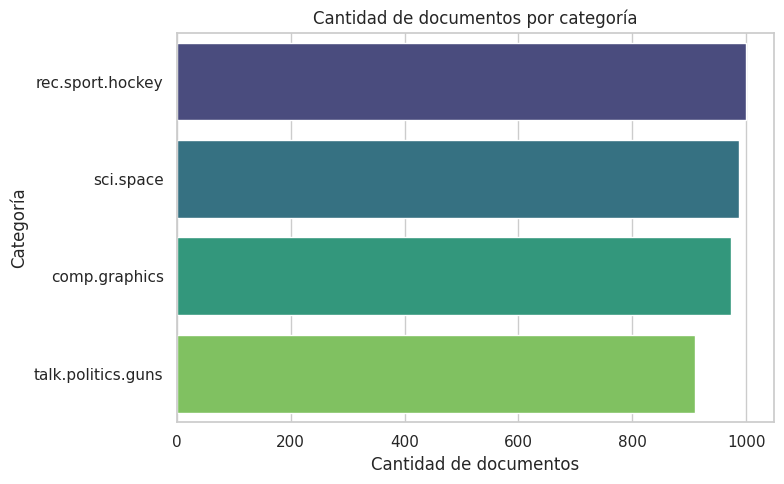

In [14]:
print("Dimensiones del dataset:", df.shape)
print()
print("Documentos por categoría:")
print(df["categoria"].value_counts())

plt.figure()
sns.countplot(data=df, y="categoria", order=df["categoria"].value_counts().index, palette="viridis")
plt.title("Cantidad de documentos por categoría")
plt.xlabel("Cantidad de documentos")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()


### 1.2 Longitud de los documentos

La longitud del texto (en palabras o caracteres) es otra variable importante: nos ayuda a decidir, por ejemplo, si conviene truncar textos muy largos o si hay documentos vacíos/basura.


In [15]:
df["n_caracteres"] = df["texto"].str.len()
df["n_palabras"] = df["texto"].str.split().apply(len)

df[["n_caracteres", "n_palabras"]].describe()


,n_caracteres,n_palabras
count,3869.00000,3869.000000
mean,1204.87206,190.404239
std,3941.77626,573.560019
min,0.00000,0.000000
25%,235.00000,40.000000
50%,482.00000,82.000000
75%,965.00000,162.000000
max,74878.00000,11251.000000


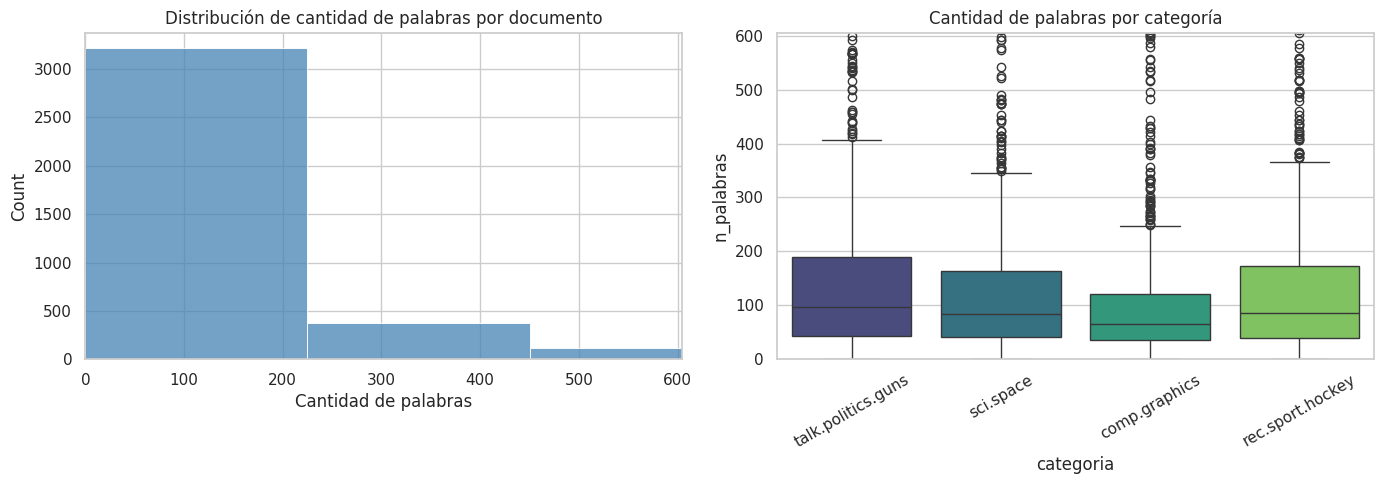

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["n_palabras"], bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Distribución de cantidad de palabras por documento")
axes[0].set_xlabel("Cantidad de palabras")
axes[0].set_xlim(0, df["n_palabras"].quantile(0.95))  # recortamos outliers para ver mejor

sns.boxplot(data=df, x="categoria", y="n_palabras", ax=axes[1], palette="viridis")
axes[1].set_title("Cantidad de palabras por categoría")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_ylim(0, df["n_palabras"].quantile(0.95))

plt.tight_layout()
plt.show()


### 1.3 ¿Hay documentos vacíos o muy cortos?

Es una buena práctica revisar si hay "basura" en el dataset antes de seguir.


In [23]:
documentos_muy_cortos = df[df["n_palabras"] < 4]
print(f"Documentos con menos de 3 palabras: {len(documentos_muy_cortos)}")

# Los eliminamos: no aportan información útil para clasificar
df = df[df["n_palabras"] >= 4].reset_index(drop=True)
print(f"Dataset final: {df.shape[0]} documentos")


Documentos con menos de 3 palabras: 0
Dataset final: 3750 documentos


In [24]:
documentos_muy_cortos

,texto,categoria,n_caracteres,n_palabras


### 1.4 Palabras más frecuentes (antes de preprocesar)

Miremos qué palabras aparecen más seguido en cada categoría, **sin limpiar nada todavía**. Esto nos va a servir después como punto de comparación: vamos a ver cómo cambia esta nube de palabras una vez que saquemos stopwords, puntuación, etc.


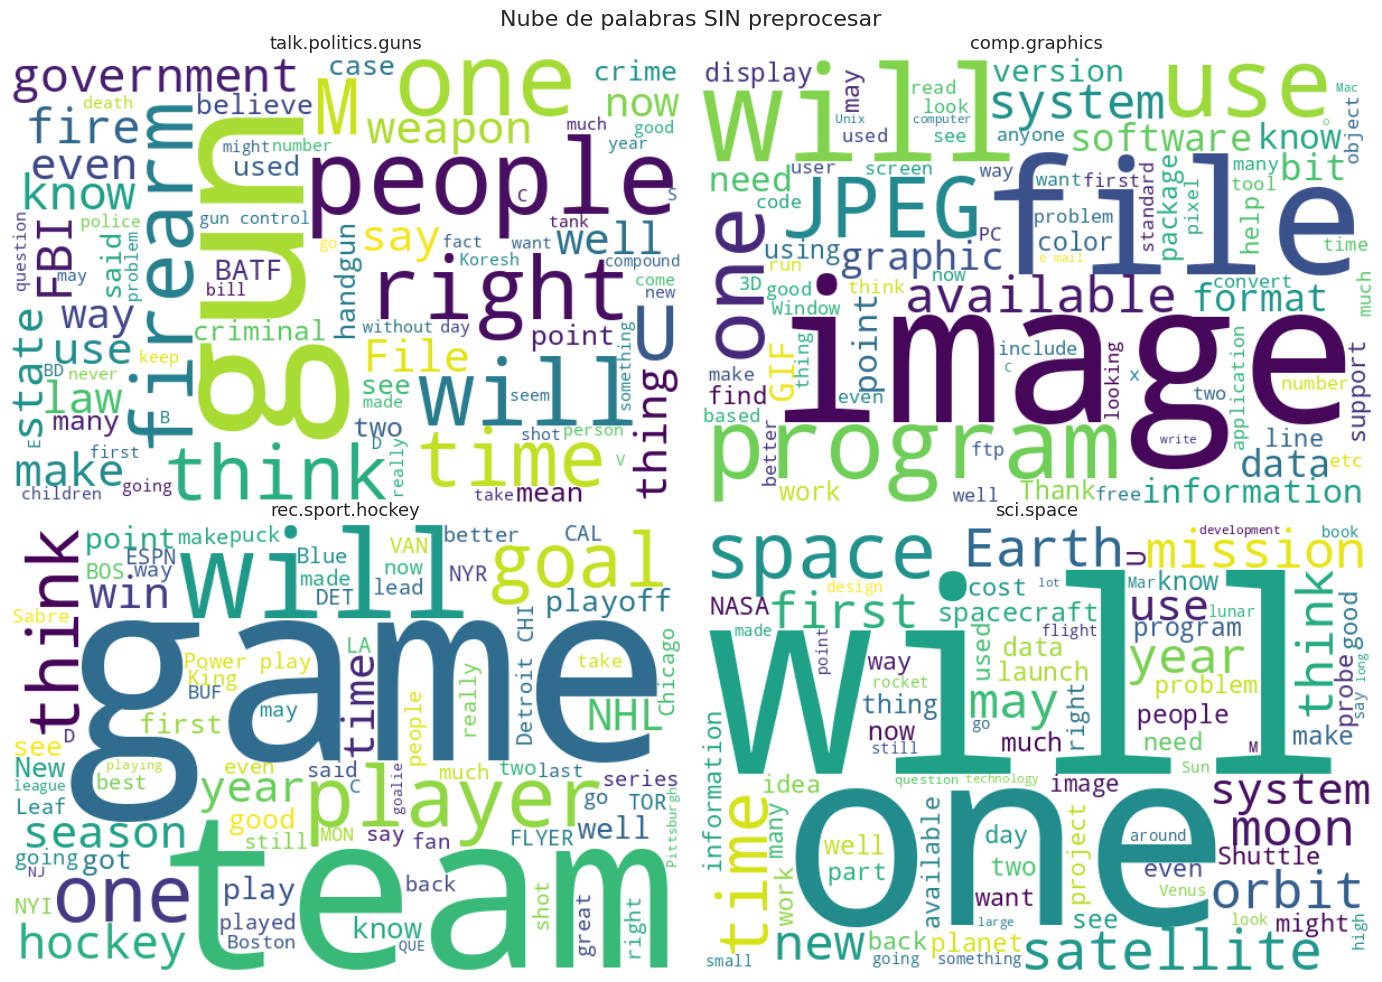

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, categoria in zip(axes, df["categoria"].unique()):
    texto_categoria = " ".join(df[df["categoria"] == categoria]["texto"].values)
    wc = WordCloud(width=600, height=400, background_color="white",
                   colormap="viridis", max_words=80).generate(texto_categoria)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(categoria, fontsize=13)
    ax.axis("off")

plt.suptitle("Nube de palabras SIN preprocesar", fontsize=16)
plt.tight_layout()
plt.show()


**Pregunta para pensar (y discutir en clase):** ¿Qué palabras aparecen en TODAS las nubes de palabras, sin importar la categoría? ¿Aportan información para diferenciar clases? Esa es exactamente la razón de ser de las *stopwords*, que vemos en el próximo bloque.


---
# Bloque 2 · Preprocesamiento de texto

Un modelo de Machine Learning no entiende texto: entiende **números**. Antes de convertir el texto en números (Bloque 3), conviene **limpiarlo y normalizarlo** para que esos números representen mejor el contenido real y no ruido.

## 2.1 Limpieza básica

Antes de cualquier técnica "de NLP", conviene hacer una limpieza simple:

- pasar todo a minúsculas (`"Hockey"` y `"hockey"` deberían ser la misma palabra),
- sacar puntuación y números,
- sacar espacios extra.

## 2.2 Tokenización

**Tokenizar** es partir un texto en unidades más chicas, generalmente palabras (*tokens*). Es el primer paso obligatorio para poder aplicar stopwords, stemming o lematización palabra por palabra.

```
"Los perros corren rápido" → ["Los", "perros", "corren", "rápido"]
```

## 2.3 Stopwords

Las **stopwords** son palabras muy frecuentes en un idioma que **no aportan significado discriminativo** para la tarea: artículos, preposiciones, pronombres (`"the"`, `"a"`, `"is"`, `"and"` en inglés; `"el"`, `"la"`, `"de"`, `"que"` en español).

¿Por qué sacarlas?
- Aparecen en TODOS los documentos, sin importar la clase → no ayudan a diferenciar categorías.
- Reducen el tamaño del vocabulario → matrices más chicas, entrenamiento más rápido.

⚠️ Ojo: sacar stopwords no siempre es gratis. En tareas donde la negación importa mucho (ej. análisis de sentimiento: *"no me gustó"*), sacar la palabra "no" puede ser contraproducente. Por eso siempre conviene **probarlo empíricamente** (¡lo vamos a hacer en el Bloque 5!).

## 2.4 Stemming vs. Lematización

Las palabras `"correr"`, `"corriendo"`, `"corrió"`, `"corredor"` están relacionadas, pero para un modelo que cuenta palabras son 4 palabras totalmente distintas. **Stemming** y **lematización** buscan resolver esto llevando las palabras a una forma común, pero lo hacen de manera muy distinta:

| | **Stemming** | **Lematización** |
|---|---|---|
| ¿Qué hace? | Corta el final de la palabra con **reglas heurísticas** (sin entender gramática) | Busca el **lema** (la forma "de diccionario") usando reglas lingüísticas reales |
| Velocidad | Muy rápido | Más lento (usa modelos de lenguaje) |
| Precisión lingüística | Baja: puede generar palabras que no existen | Alta: siempre devuelve una palabra real |
| Ejemplo (`"studies"`) | `"studi"` | `"study"` |
| Ejemplo (`"better"`) | `"better"` (no lo detecta como comparativo) | `"good"` |
| Librería típica | `nltk` (`PorterStemmer`, `SnowballStemmer`) | `spaCy` |

En resumen: el *stemming* es una tijera rápida y un poco bruta; la lematización es un diccionario inteligente, más lento pero más preciso.

Vamos a implementar las dos y comparar resultados sobre las mismas frases.


In [27]:
def limpiar_texto(texto):
    """Limpieza básica: minúsculas, sin puntuación ni números, sin espacios extra."""
    texto = texto.lower()
    texto = re.sub(r"[^a-záéíóúñ\s]", " ", texto)   # saca números y puntuación
    texto = re.sub(r"\s+", " ", texto).strip()       # colapsa espacios múltiples
    return texto


ejemplo = "The players' 3 best runners were RUNNING and studying strategies!!"
print("Original: ", ejemplo)
print("Limpio:   ", limpiar_texto(ejemplo))


Original:  The players' 3 best runners were RUNNING and studying strategies!!
Limpio:    the players best runners were running and studying strategies


In [28]:
stop_words_en = set(stopwords.words("english"))
print(f"Cantidad de stopwords en inglés: {len(stop_words_en)}")
print("Algunos ejemplos:", list(stop_words_en)[:15])


def sacar_stopwords(tokens, stopwords_set=stop_words_en):
    return [t for t in tokens if t not in stopwords_set]


tokens_ejemplo = word_tokenize(limpiar_texto(ejemplo))
print("\nTokens:", tokens_ejemplo)
print("Sin stopwords:", sacar_stopwords(tokens_ejemplo))


Cantidad de stopwords en inglés: 198
Algunos ejemplos: ['y', 'whom', 'has', "we'll", 'doing', 'ourselves', "they're", 'only', 'did', 'and', 'is', 'do', "mightn't", 'any', 'he']

Tokens: ['the', 'players', 'best', 'runners', 'were', 'running', 'and', 'studying', 'strategies']
Sin stopwords: ['players', 'best', 'runners', 'running', 'studying', 'strategies']


In [29]:
stemmer = PorterStemmer()

def stemizar(tokens):
    return [stemmer.stem(t) for t in tokens]


def lematizar(tokens):
    # spaCy trabaja mejor sobre el texto completo (usa contexto), no token por token
    doc = nlp(" ".join(tokens))
    return [tok.lemma_ for tok in doc]


# Comparación lado a lado sobre varias palabras con la misma raíz semántica
palabras_prueba = ["running", "runs", "ran", "runner", "studies", "studying",
                    "better", "was", "mice", "argument", "arguing"]

comparacion = pd.DataFrame({
    "palabra": palabras_prueba,
    "stemming (Porter)": stemizar(palabras_prueba),
    "lematización (spaCy)": lematizar(palabras_prueba)
})
comparacion


,palabra,stemming (Porter),lematización (spaCy)
0,running,run,run
1,runs,run,run
2,ran,ran,run
3,runner,runner,runner
4,studies,studi,study
5,studying,studi,study
6,better,better,well
7,was,wa,be
8,mice,mice,mice
9,argument,argument,argument


**Mirá la tabla anterior con atención:**

- Comparar los resultados de hacer stemming y lematización
### 🔧 EJERCICIO
Probá con tus propias palabras en la lista `palabras_prueba` (podés usar palabras en español si querés, pero acordate que el `stemmer` y `nlp` están configurados en inglés). ¿Encontrás algún caso donde el stemming se "equivoque" de forma graciosa?


In [ ]:
# 🔧 Espacio para tu experimento
mis_palabras = ["", "", ""]  # completá acá
# print(pd.DataFrame({"palabra": mis_palabras, "stem": stemizar(mis_palabras), "lema": lematizar(mis_palabras)}))


## 2.5 Armamos las pipelines de preprocesamiento completas

Vamos a definir varias funciones de preprocesamiento, cada una aplicando un nivel distinto de "limpieza", para poder **comparar su impacto en el modelo final** (eso lo hacemos en el Bloque 5):

1. `preprocesar_basico`: solo limpieza (minúsculas, sin puntuación/números).
2. `preprocesar_stopwords`: limpieza + sacar stopwords.
3. `preprocesar_stemming`: limpieza + stopwords + stemming.
4. `preprocesar_lematizacion`: limpieza + stopwords + lematización.


In [30]:
def preprocesar_basico(texto):
    return limpiar_texto(texto)


def preprocesar_stopwords(texto):
    tokens = word_tokenize(limpiar_texto(texto))
    tokens = sacar_stopwords(tokens)
    return " ".join(tokens)


def preprocesar_stemming(texto):
    tokens = word_tokenize(limpiar_texto(texto))
    tokens = sacar_stopwords(tokens)
    tokens = stemizar(tokens)
    return " ".join(tokens)


def preprocesar_lematizacion(texto):
    tokens = word_tokenize(limpiar_texto(texto))
    tokens = sacar_stopwords(tokens)
    tokens = lematizar(tokens)
    return " ".join(tokens)


# Probemos las 4 versiones sobre un documento real del dataset
doc_ejemplo = df["texto"].iloc[0]
print("ORIGINAL:\n", doc_ejemplo[:300], "...\n")
print("BÁSICO:\n", preprocesar_basico(doc_ejemplo)[:300], "...\n")
print("SIN STOPWORDS:\n", preprocesar_stopwords(doc_ejemplo)[:300], "...\n")
print("STEMMING:\n", preprocesar_stemming(doc_ejemplo)[:300], "...\n")
print("LEMATIZACIÓN:\n", preprocesar_lematizacion(doc_ejemplo)[:300], "...")


ORIGINAL:
 [... snip ...]


Can you imagine what happens when a magazine explodes? Bullets go flying every
where. IMHO, these "gunshot wounds" were actually caused when the magazines 
went up. A Texas ranger does not a pathologist make, so I'll wait for an
autopsy to determine if they were shot first.  ...

BÁSICO:
 snip can you imagine what happens when a magazine explodes bullets go flying every where imho these gunshot wounds were actually caused when the magazines went up a texas ranger does not a pathologist make so i ll wait for an autopsy to determine if they were shot first ...

SIN STOPWORDS:
 snip imagine happens magazine explodes bullets go flying every imho gunshot wounds actually caused magazines went texas ranger pathologist make wait autopsy determine shot first ...

STEMMING:
 snip imagin happen magazin explod bullet go fli everi imho gunshot wound actual caus magazin went texa ranger pathologist make wait autopsi determin shot first ...

LEMATIZACIÓN:
 snip imagine hap

> ⏱️ **Nota de performance:** aplicar `spaCy` documento por documento puede ser lento sobre miles de documentos. Para la clase vamos a trabajar con una muestra del dataset para que los tiempos de espera sean razonables. En un proyecto real, se puede acelerar usando `nlp.pipe()` (procesamiento en batch) o `n_process` para paralelizar.


In [37]:
# Tomamos una muestra para que el procesamiento con spaCy sea ágil durante la clase
N_MUESTRA = 8000
df_muestra = df.groupby("categoria", group_keys=False).apply(
    lambda x: x.sample(min(len(x), N_MUESTRA // df["categoria"].nunique()), random_state=42)
).reset_index(drop=True)

print("Tamaño de la muestra:", df_muestra.shape)
print(df_muestra["categoria"].value_counts())


Tamaño de la muestra: (3750, 4)
categoria
rec.sport.hockey      970
sci.space             951
comp.graphics         948
talk.politics.guns    881
Name: count, dtype: int64


In [38]:
# Aplicamos las 4 versiones de preprocesamiento a toda la muestra (puede tardar 1-2 minutos)
df_muestra["texto_basico"] = df_muestra["texto"].apply(preprocesar_basico)
df_muestra["texto_sin_stopwords"] = df_muestra["texto"].apply(preprocesar_stopwords)
df_muestra["texto_stemming"] = df_muestra["texto"].apply(preprocesar_stemming)
df_muestra["texto_lematizado"] = df_muestra["texto"].apply(preprocesar_lematizacion)

df_muestra.head(3)


,texto,categoria,n_caracteres,n_palabras,texto_basico,texto_sin_stopwords,texto_stemming,texto_lematizado
0,Try WinJPEG on oak.oakland.edu:pub/msdos/win...,comp.graphics,163,20,try winjpeg on oak oakland edu pub msdos windo...,try winjpeg oak oakland edu pub msdos windows ...,tri winjpeg oak oakland edu pub msdo window wi...,try winjpeg oak oakland edu pub msdo windows w...
1,Reposted by request ... these images are great...,comp.graphics,3184,428,reposted by request these images are great but...,reposted request images great also large x pix...,repost request imag great also larg x pixel ty...,reposte request image great also large x pixel...
2,How can I find these files and graphics that p...,comp.graphics,585,106,how can i find these files and graphics that p...,find files graphics people downloading unix sy...,find file graphic peopl download unix system d...,find file graphic people download unix system ...


### 2.6 ¿Cuánto se redujo el vocabulario con cada técnica?

Una forma concreta de ver el impacto del preprocesamiento: contar cuántas **palabras únicas (vocabulario)** queda en cada versión del texto. Menos vocabulario generalmente significa una matriz de features más chica y más manejable.


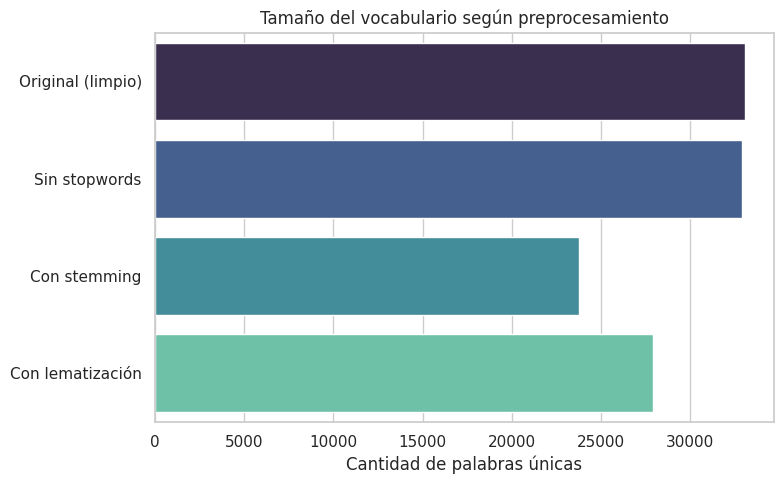

{'Original (limpio)': 33060,
 'Sin stopwords': 32906,
 'Con stemming': 23784,
 'Con lematización': 27914}

In [39]:
def tamano_vocabulario(serie_textos):
    vocab = set()
    for texto in serie_textos:
        vocab.update(texto.split())
    return len(vocab)

vocabularios = {
    "Original (limpio)": tamano_vocabulario(df_muestra["texto_basico"]),
    "Sin stopwords": tamano_vocabulario(df_muestra["texto_sin_stopwords"]),
    "Con stemming": tamano_vocabulario(df_muestra["texto_stemming"]),
    "Con lematización": tamano_vocabulario(df_muestra["texto_lematizado"]),
}

plt.figure()
sns.barplot(x=list(vocabularios.values()), y=list(vocabularios.keys()), palette="mako")
plt.title("Tamaño del vocabulario según preprocesamiento")
plt.xlabel("Cantidad de palabras únicas")
plt.tight_layout()
plt.show()

vocabularios


**Para discutir:** ¿por qué el stemming reduce el vocabulario más que la lematización? *(Pista: el stemming es más agresivo agrupando palabras distintas bajo la misma raíz, incluso cuando esa raíz no es una palabra real).*


---
# Bloque 3 · De texto a números: CountVectorizer y TF-IDF

Ya tenemos el texto limpio. Ahora necesitamos convertirlo en una **matriz numérica**, porque Naive Bayes y Regresión Logística (como casi todos los modelos de ML) solo trabajan con números.

La familia de técnicas que vamos a usar se llama **Bag of Words** (bolsa de palabras): la idea es representar cada documento por **qué palabras contiene y cuántas veces**, ignorando completamente el orden de las palabras.

## 3.1 CountVectorizer

`CountVectorizer` arma una tabla donde:
- cada **fila** es un documento,
- cada **columna** es una palabra del vocabulario,
- cada **celda** es la cantidad de veces que esa palabra aparece en ese documento.

```
Documentos:
  D1: "el gato come pescado"
  D2: "el perro come carne"

Vocabulario: [carne, come, el, gato, pescado, perro]

           carne  come  el  gato  pescado  perro
    D1       0      1    1    1      1       0
    D2       1      1    1    0      0       1
```

Parámetros importantes que vamos a usar:
- `max_features`: nos quedamos solo con las N palabras más frecuentes (controla el tamaño del vocabulario).
- `ngram_range`: además de palabras sueltas (*unigramas*), podemos incluir pares de palabras consecutivas (*bigramas*), por ejemplo `"no me gusta"` → el bigrama `"no_me"` captura algo que la palabra `"no"` sola no captura.
- `min_df` / `max_df`: ignoran palabras demasiado raras (aparecen en muy pocos documentos) o demasiado comunes (aparecen en casi todos, como stopwords residuales).

## 3.2 TF-IDF (*Term Frequency – Inverse Document Frequency*)

El problema de `CountVectorizer` es que le da el mismo "peso" a todas las palabras frecuentes, incluso si esa palabra aparece en casi todos los documentos (y por lo tanto no ayuda a diferenciarlos). **TF-IDF** corrige esto ponderando cada palabra según qué tan "especial" es:

$$
\text{TF-IDF}(t, d) = \text{TF}(t, d) \times \text{IDF}(t)
$$

- **TF (Term Frequency):** qué tan frecuente es la palabra *t* dentro del documento *d*. Cuanto más se repite dentro del documento, más importante parece ser para ese documento.
- **IDF (Inverse Document Frequency):**

$$
\text{IDF}(t) = \log\left(\frac{N}{\text{documentos que contienen } t}\right)
$$

donde *N* es el total de documentos. Si una palabra aparece en **todos** los documentos, su IDF es cercano a 0 (no discrimina nada). Si aparece en **pocos** documentos, su IDF es alto (es una palabra "distintiva").

**Intuición:** TF-IDF le baja el volumen a las palabras comunes (tipo "the", "is") y le sube el volumen a palabras raras pero repetidas dentro de un documento puntual (que probablemente sean el tema central de ese documento).

Vamos a comparar ambas técnicas empíricamente en el Bloque 5.


In [50]:
# --- Ejemplo didáctico chiquito, a mano, para ver la diferencia CountVectorizer vs TF-IDF ---
corpus_ejemplo = [
    "el gato come pescado todos los dias",
    "el perro come carne todos los dias",
    "el gato y el perro juegan en el patio"
]

count_vec = CountVectorizer()
X_count_ejemplo = count_vec.fit_transform(corpus_ejemplo)

tfidf_vec = TfidfVectorizer(norm=None, smooth_idf=False, sublinear_tf =False)
X_tfidf_ejemplo = tfidf_vec.fit_transform(corpus_ejemplo)

print("=== CountVectorizer ===")
display(pd.DataFrame(X_count_ejemplo.toarray(), columns=count_vec.get_feature_names_out()))

print("\n=== TF-IDF ===")
display(pd.DataFrame(np.round(X_tfidf_ejemplo.toarray(), 2), columns=tfidf_vec.get_feature_names_out()))


=== CountVectorizer ===


,carne,come,dias,el,en,gato,juegan,los,patio,perro,pescado,todos
0,0,1,1,1,0,1,0,1,0,0,1,1
1,1,1,1,1,0,0,0,1,0,1,0,1
2,0,0,0,3,1,1,1,0,1,1,0,0



=== TF-IDF ===


,carne,come,dias,el,en,gato,juegan,los,patio,perro,pescado,todos
0,0.0,1.41,1.41,1.0,0.0,1.41,0.0,1.41,0.0,0.00,2.1,1.41
1,2.1,1.41,1.41,1.0,0.0,0.00,0.0,1.41,0.0,1.41,0.0,1.41
2,0.0,0.00,0.00,3.0,2.1,1.41,2.1,0.00,2.1,1.41,0.0,0.00


In [51]:
tfidf_vec.idf_

array([2.09861229, 1.40546511, 1.40546511, 1.        , 2.09861229,
       1.40546511, 2.09861229, 1.40546511, 2.09861229, 1.40546511,
       2.09861229, 1.40546511])

In [43]:
tfidf_vec.get_feature_names_out()

array(['carne', 'come', 'dias', 'el', 'en', 'gato', 'juegan', 'los',
       'patio', 'perro', 'pescado', 'todos'], dtype=object)

Fijate cómo la palabra `"el"` (que aparece en las 3 frases) tiene un valor bajo en la matriz TF-IDF a pesar de repetirse mucho, mientras que palabras como `"gato"` o `"perro"` (que no están en todos los documentos) tienen más peso relativo. Eso es exactamente lo que buscábamos.

### 🔧 EJERCICIO
Agregá una cuarta frase al `corpus_ejemplo` que repita mucho una palabra nueva (por ejemplo, "pizza pizza pizza") y volvé a correr la celda. ¿Qué pasa con el valor de TF-IDF de esa palabra comparado con las demás?


## 3.3 Vectorizando el dataset real

Ahora sí, apliquemos `CountVectorizer` y `TfidfVectorizer` sobre nuestro dataset real (ya preprocesado) y miremos las palabras más "importantes" del vocabulario resultante.


Forma de la matriz TF-IDF: (3750, 5000)
(filas = documentos, columnas = palabras/bigramas del vocabulario)


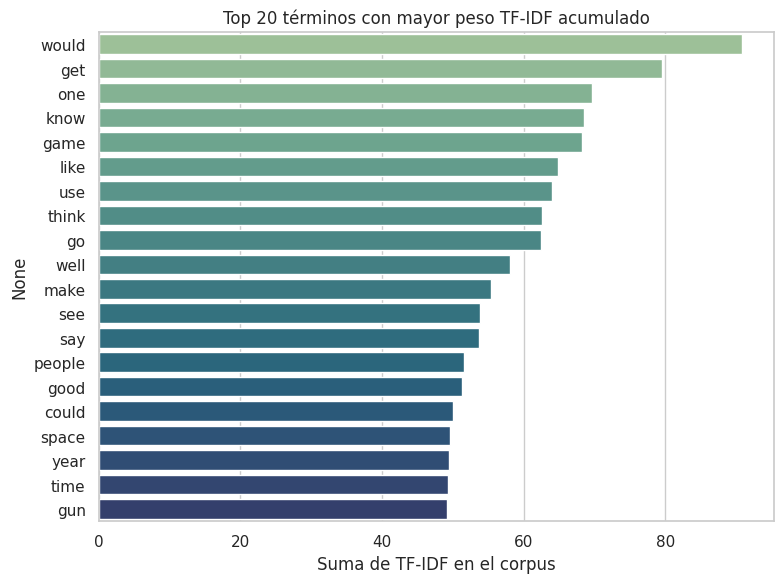

In [52]:
tfidf_demo = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.9)
X_tfidf_demo = tfidf_demo.fit_transform(df_muestra["texto_lematizado"])

print("Forma de la matriz TF-IDF:", X_tfidf_demo.shape)
print("(filas = documentos, columnas = palabras/bigramas del vocabulario)")

# Palabras con mayor IDF promedio ponderado por su presencia => las más "distintivas" en general
suma_tfidf = np.asarray(X_tfidf_demo.sum(axis=0)).flatten()
top_palabras = pd.Series(suma_tfidf, index=tfidf_demo.get_feature_names_out()).sort_values(ascending=False).head(20)

plt.figure(figsize=(8, 6))
sns.barplot(x=top_palabras.values, y=top_palabras.index, palette="crest")
plt.title("Top 20 términos con mayor peso TF-IDF acumulado")
plt.xlabel("Suma de TF-IDF en el corpus")
plt.tight_layout()
plt.show()


---
# Bloque 4 · Los modelos: Naive Bayes y Regresión Logística

Ya sabemos cómo convertir texto en una matriz de números. Ahora, ¿cómo usamos esa matriz para **predecir una categoría**?

## 4.1 Naive Bayes (Multinomial)

Se basa en el **Teorema de Bayes**:

$$
P(\text{clase} \mid \text{documento}) = \frac{P(\text{documento} \mid \text{clase}) \cdot P(\text{clase})}{P(\text{documento})}
$$

En palabras: *"la probabilidad de que el documento sea de la clase C, dado el texto que tiene, depende de qué tan probable es ver ese texto en documentos de la clase C, multiplicado por qué tan frecuente es la clase C en general"*.

El adjetivo **"naive" (ingenuo)** viene de un supuesto simplificador: asume que **todas las palabras son independientes entre sí** dado la clase. Es decir, que la presencia de la palabra "gol" no tiene relación con la presencia de la palabra "cancha" más allá de que ambas sean típicas de la clase "deportes". Esto obviamente no es 100% cierto en el lenguaje real (las palabras sí se relacionan entre sí), pero en la práctica **funciona sorprendentemente bien para texto**, es muy rápido de entrenar, y necesita poca cantidad de datos.

La variante **Multinomial** (`MultinomialNB`) es la más usada para texto porque modela directamente **conteos/frecuencias de palabras**, que es justo lo que producen `CountVectorizer` y `TfidfVectorizer`.

**Hiperparámetro clave:** `alpha` (suavizado de Laplace). Evita que una palabra nunca vista en entrenamiento para una clase determinada le asigne probabilidad 0 a esa clase (lo cual rompería toda la predicción). Cuanto más alto `alpha`, más "conservador"/suavizado es el modelo.

## 4.2 Regresión Logística

A diferencia de Naive Bayes (que es un modelo *generativo*, modela cómo se generan los datos), la Regresión Logística es un modelo ***discriminativo***: aprende directamente una función que separa las clases.

Para clasificación binaria, calcula una combinación lineal de las features (en nuestro caso, los valores de TF-IDF/conteos de cada palabra) y la pasa por la función **sigmoide** para obtener una probabilidad entre 0 y 1:

$$
P(y=1 \mid x) = \sigma(w \cdot x + b) = \frac{1}{1 + e^{-(w \cdot x + b)}}
$$

Cada palabra tiene un **peso ($w_i$)** aprendido: palabras muy asociadas a una clase tendrán pesos con valor absoluto alto (positivo o negativo). Esto es muy útil para **interpretar el modelo** (lo vamos a explotar en el Bloque 7: "¿qué palabras usa el modelo para decidir?").

Para más de 2 clases (nuestro caso: 4 categorías), `scikit-learn` extiende esto automáticamente (estrategia multinomial/one-vs-rest).

**Hiperparámetro clave:** `C` (inverso de la regularización). Un `C` bajo fuerza al modelo a usar pesos más chicos (menos "confianza" en pocas palabras, más generalización); un `C` alto le permite ajustar más los pesos a los datos de entrenamiento (riesgo de sobreajuste).

## 4.3 ¿Cuál "conviene" para texto?

No hay una respuesta única, ¡por eso los vamos a comparar empíricamente!

| | Naive Bayes | Regresión Logística |
|---|---|---|
| Velocidad de entrenamiento | Muy rápida | Rápida (un poco más lenta) |
| Funciona bien con poco dato | Sí, muy bien | Necesita algo más de datos |
| Supuesto de independencia entre palabras | Sí (simplificador) | No |
| Interpretabilidad | Media (probabilidades por palabra) | Alta (pesos claros por palabra) |
| Sensible a features correlacionadas | Menos | Más |

En la práctica, para clasificación de texto ambos suelen ser **baselines muy fuertes**, difíciles de superar incluso con modelos más complejos, cuando el dataset no es gigante.


---
# Bloque 5 · Experimentando: ¿qué combinación funciona mejor?

Ya tenemos todas las piezas:
- **4 formas de preprocesar** el texto (básico, sin stopwords, stemming, lematización),
- **2 formas de vectorizar** (`CountVectorizer`, `TfidfVectorizer`),
- **2 modelos** (`MultinomialNB`, `LogisticRegression`).

Eso son **4 × 2 × 2 = 16 combinaciones posibles**. En vez de probarlas "a mano" una por una, vamos a armar un experimento sistemático: entrenamos las 16 combinaciones sobre el mismo split de train/test y comparamos sus métricas.

### Separando entrenamiento y test

Como siempre en ML, separamos una porción de los datos que el modelo **no va a ver durante el entrenamiento**, para poder evaluar qué tan bien generaliza.


In [80]:
X = df_muestra[["texto_basico", "texto_sin_stopwords", "texto_stemming", "texto_lematizado"]]
y = df_muestra["categoria"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y  # stratify mantiene el balance de clases en ambos splits
)

print("Train:", X_train.shape[0], "documentos")
print("Test: ", X_test.shape[0], "documentos")


Train: 2812 documentos
Test:  938 documentos


In [81]:
y_test.value_counts()/len(y_test)

,count
categoria,
rec.sport.hockey,0.259062
sci.space,0.253731
comp.graphics,0.252665
talk.politics.guns,0.234542


In [82]:
y_train.value_counts()/len(y_train)

,count
categoria,
rec.sport.hockey,0.258535
sci.space,0.253556
comp.graphics,0.252845
talk.politics.guns,0.235064


> 📌 **`stratify=y`**: le pedimos a `train_test_split` que mantenga la misma proporción de cada categoría en train y test que en el dataset original. Es importante para no distorsionar la comparación.


In [83]:
def entrenar_y_evaluar(texto_train, texto_test, y_train, y_test, vectorizador, modelo):
    """Entrena un vectorizador+modelo y devuelve las métricas en test."""
    X_train_vec = vectorizador.fit_transform(texto_train)
    X_test_vec = vectorizador.transform(texto_test)

    modelo.fit(X_train_vec, y_train)
    y_pred = modelo.predict(X_test_vec)

    accuracy = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")

    return {
        "accuracy": accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
    }, y_pred


In [84]:
preprocesamientos = {
    "Básico": "texto_basico",
    "Sin stopwords": "texto_sin_stopwords",
    "Stemming": "texto_stemming",
    "Lematización": "texto_lematizado",
}

vectorizadores = {
    "CountVectorizer": lambda: CountVectorizer(max_features=5000),
    "TF-IDF": lambda: TfidfVectorizer(max_features=5000),
}

modelos = {
    "Naive Bayes": lambda: MultinomialNB(),
    "Regresión Logística": lambda: LogisticRegression(max_iter=1000, random_state=42),
}

resultados = []

for nombre_prep, columna in preprocesamientos.items():
    for nombre_vec, crear_vec in vectorizadores.items():
        for nombre_modelo, crear_modelo in modelos.items():
            metricas, _ = entrenar_y_evaluar(
                X_train[columna], X_test[columna], y_train, y_test,
                crear_vec(), crear_modelo()
            )
            resultados.append({
                "preprocesamiento": nombre_prep,
                "vectorizador": nombre_vec,
                "modelo": nombre_modelo,
                **metricas
            })

df_resultados = pd.DataFrame(resultados).sort_values("f1_macro", ascending=False).reset_index(drop=True)
df_resultados


,preprocesamiento,vectorizador,modelo,accuracy,precision_macro,recall_macro,f1_macro
0,Lematización,TF-IDF,Naive Bayes,0.925373,0.925845,0.925250,0.925173
1,Stemming,TF-IDF,Naive Bayes,0.924307,0.924959,0.924195,0.924229
2,Sin stopwords,TF-IDF,Regresión Logística,0.921109,0.922699,0.920631,0.921261
3,Sin stopwords,TF-IDF,Naive Bayes,0.918977,0.919874,0.918943,0.918801
4,Stemming,TF-IDF,Regresión Logística,0.913646,0.915951,0.913089,0.913870
5,Stemming,CountVectorizer,Naive Bayes,0.913646,0.913705,0.914030,0.913388
6,Básico,TF-IDF,Naive Bayes,0.913646,0.914183,0.913789,0.913278
7,Lematización,CountVectorizer,Naive Bayes,0.912580,0.912533,0.912932,0.912203
8,Lematización,TF-IDF,Regresión Logística,0.910448,0.913685,0.909908,0.911011
9,Sin stopwords,CountVectorizer,Naive Bayes,0.909382,0.909853,0.909931,0.909037


In [85]:

df_resultados = pd.DataFrame(resultados).sort_values("accuracy", ascending=False).reset_index(drop=True)
df_resultados

,preprocesamiento,vectorizador,modelo,accuracy,precision_macro,recall_macro,f1_macro
0,Lematización,TF-IDF,Naive Bayes,0.925373,0.925845,0.925250,0.925173
1,Stemming,TF-IDF,Naive Bayes,0.924307,0.924959,0.924195,0.924229
2,Sin stopwords,TF-IDF,Regresión Logística,0.921109,0.922699,0.920631,0.921261
3,Sin stopwords,TF-IDF,Naive Bayes,0.918977,0.919874,0.918943,0.918801
4,Stemming,CountVectorizer,Naive Bayes,0.913646,0.913705,0.914030,0.913388
5,Stemming,TF-IDF,Regresión Logística,0.913646,0.915951,0.913089,0.913870
6,Básico,TF-IDF,Naive Bayes,0.913646,0.914183,0.913789,0.913278
7,Lematización,CountVectorizer,Naive Bayes,0.912580,0.912533,0.912932,0.912203
8,Lematización,TF-IDF,Regresión Logística,0.910448,0.913685,0.909908,0.911011
9,Sin stopwords,CountVectorizer,Naive Bayes,0.909382,0.909853,0.909931,0.909037


### 5.1 Visualizando la comparación

Con una tabla de 16 filas es difícil sacar conclusiones a simple vista. Grafiquemos.


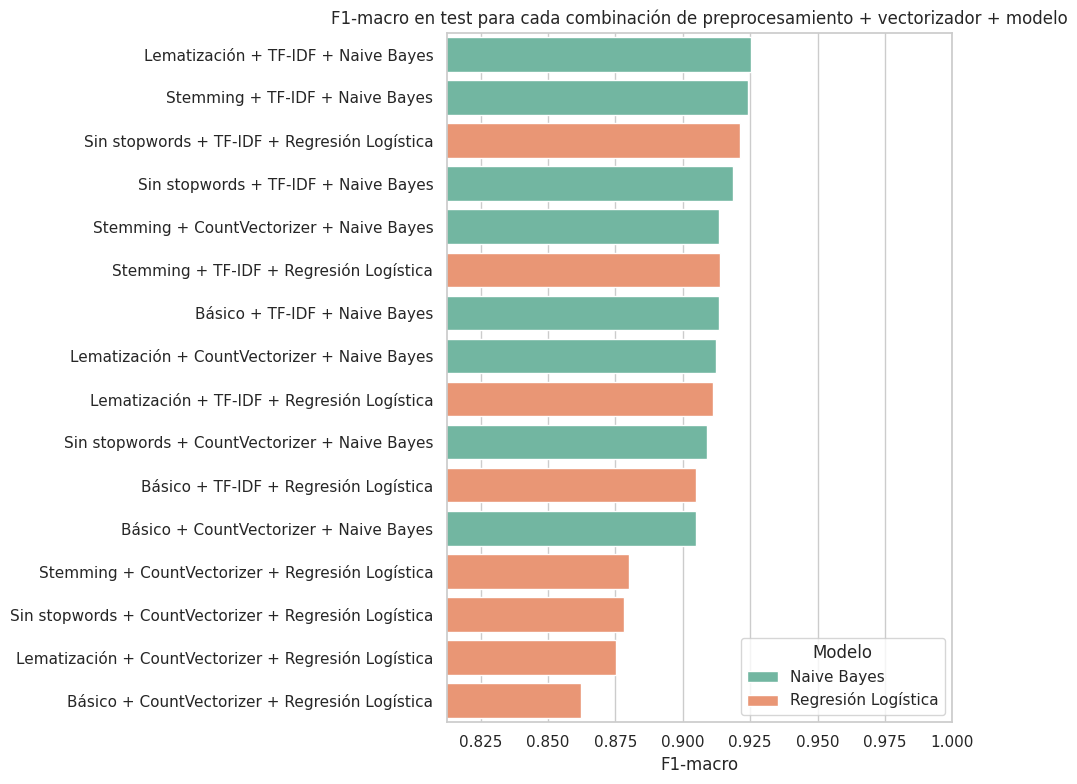

In [86]:
df_resultados["combinacion"] = (
    df_resultados["preprocesamiento"] + " + " + df_resultados["vectorizador"] + " + " + df_resultados["modelo"]
)

plt.figure(figsize=(10, 8))
sns.barplot(data=df_resultados, x="f1_macro", y="combinacion", hue="modelo", dodge=False, palette="Set2")
plt.title("F1-macro en test para cada combinación de preprocesamiento + vectorizador + modelo")
plt.xlabel("F1-macro")
plt.ylabel("")
plt.xlim(df_resultados["f1_macro"].min() - 0.05, 1.0)
plt.legend(title="Modelo", loc="lower right")
plt.tight_layout()
plt.show()


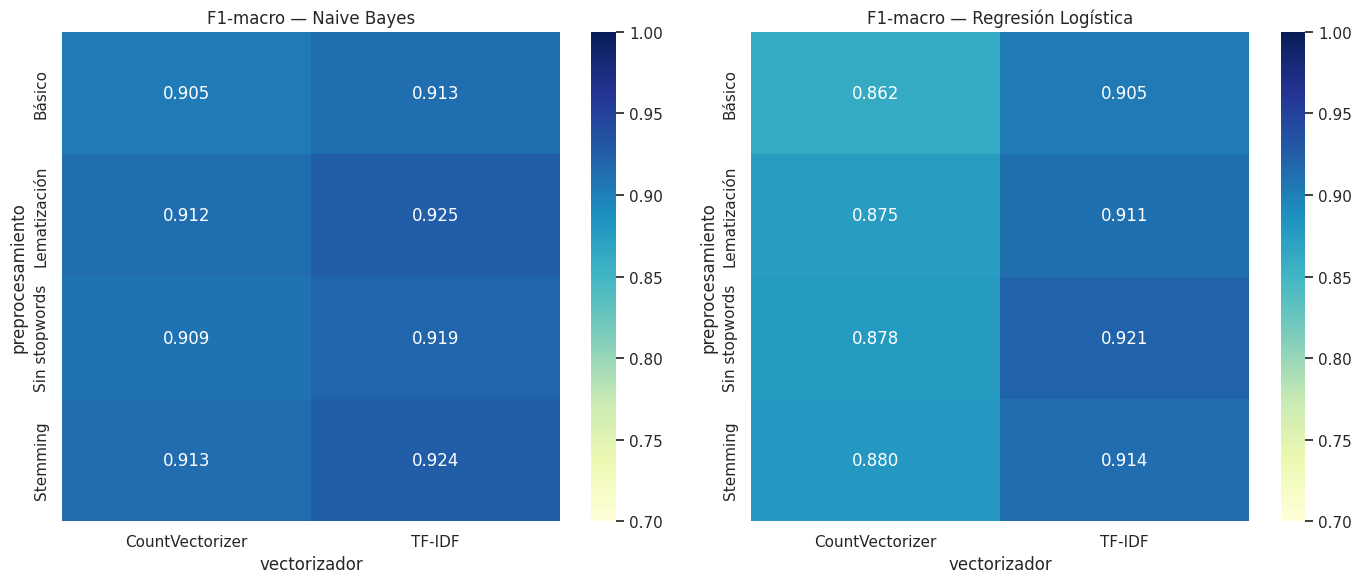

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, modelo in zip(axes, df_resultados["modelo"].unique()):
    subset = df_resultados[df_resultados["modelo"] == modelo]
    tabla_pivot = subset.pivot(index="preprocesamiento", columns="vectorizador", values="f1_macro")
    sns.heatmap(tabla_pivot, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax, vmin=0.7, vmax=1.0)
    ax.set_title(f"F1-macro — {modelo}")

plt.tight_layout()
plt.show()


### Para discutir en clase

- ¿El preprocesamiento más "agresivo" (stemming/lematización) siempre mejora el resultado? ¿Por qué podría **no** mejorar sobre un dataset donde el vocabulario ya es bastante limpio (como noticias de foros técnicos)?
- ¿TF-IDF le gana sistemáticamente a CountVectorizer, o depende del modelo?
- ¿Cambia mucho el resultado entre Naive Bayes y Regresión Logística con esta cantidad de datos?

> 💡 Este tipo de "barrido" sistemático (probar todas las combinaciones razonables y medir) es una práctica central en ML aplicado: **antes de asumir qué preprocesamiento es "mejor", se mide.**


---
# Bloque 6 · Búsqueda de hiperparámetros

Hasta ahora usamos valores "por defecto" o elegidos a mano (`max_features=5000`, `alpha` por defecto de Naive Bayes, `C=1.0` de Regresión Logística). Pero, ¿cómo sabemos que esos son los mejores valores? Para eso existe la **búsqueda de hiperparámetros**.

## 6.1 ¿Qué es un `Pipeline`?

Un `Pipeline` de `scikit-learn` encadena varios pasos (por ejemplo: vectorizador → modelo) en un solo objeto. Ventajas:
- evita errores de "fuga de información" (*data leakage*): el vectorizador se ajusta (`fit`) **solo** con datos de entrenamiento en cada fold de validación cruzada, nunca con el test,
- permite buscar hiperparámetros de **todos los pasos a la vez** (los del vectorizador y los del modelo).

## 6.2 ¿Qué es `GridSearchCV`?

`GridSearchCV` prueba **todas las combinaciones posibles** de un conjunto de hiperparámetros que le indiquemos, usando **validación cruzada** (*cross-validation*, CV): en vez de medir sobre un único split train/test, parte el set de entrenamiento en *k* "pliegues" (folds), entrena en *k-1* y valida en el restante, rotando, y promedia el resultado. Esto da una estimación más confiable del rendimiento real que un solo split.

Vamos a usar `StratifiedKFold` (mantiene el balance de clases en cada fold) con `k=5`.

> ⚠️ `GridSearchCV` prueba **todas** las combinaciones del grid: si tenés muchos hiperparámetros con muchos valores posibles, puede tardar mucho. Para grids muy grandes existe `RandomizedSearchCV`, que prueba una muestra aleatoria de combinaciones en vez de todas — útil cuando el espacio de búsqueda es enorme.

Vamos a optimizar la combinación que dio mejores resultados en el Bloque 5 (ajustá `mejor_preprocesamiento` según lo que hayas visto en tus gráficos).


In [88]:
# Tomamos la mejor combinación de preprocesamiento según el bloque anterior
mejor_fila = df_resultados.iloc[0]
print("Mejor combinación encontrada en el Bloque 5:")
print(mejor_fila[["preprocesamiento", "vectorizador", "modelo", "f1_macro"]])

columna_texto = preprocesamientos[mejor_fila["preprocesamiento"]]
texto_train_final = X_train[columna_texto]
texto_test_final = X_test[columna_texto]


Mejor combinación encontrada en el Bloque 5:
preprocesamiento    Lematización
vectorizador              TF-IDF
modelo               Naive Bayes
f1_macro                0.925173
Name: 0, dtype: object


### 6.3 Grid de hiperparámetros — Naive Bayes


In [89]:
pipeline_nb = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", MultinomialNB())
])

grid_nb = {
    "tfidf__max_features": [2000, 5000, None],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2, 5],
    "clf__alpha": [0.1, 0.5, 1.0, 2.0],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

busqueda_nb = GridSearchCV(
    pipeline_nb, grid_nb, cv=cv, scoring="f1_macro", n_jobs=-1, verbose=1
)
busqueda_nb.fit(texto_train_final, y_train)

print("Mejores hiperparámetros (Naive Bayes):", busqueda_nb.best_params_)
print(f"Mejor F1-macro en validación cruzada: {busqueda_nb.best_score_:.4f}")


Fitting 5 folds for each of 72 candidates, totalling 360 fits
Mejores hiperparámetros (Naive Bayes): {'clf__alpha': 0.1, 'tfidf__max_features': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
Mejor F1-macro en validación cruzada: 0.9383


In [97]:
pd.DataFrame(busqueda_nb.cv_results_).columns

Index(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time',
       'param_clf__alpha', 'param_tfidf__max_features', 'param_tfidf__min_df',
       'param_tfidf__ngram_range', 'params', 'split0_test_score',
       'split1_test_score', 'split2_test_score', 'split3_test_score',
       'split4_test_score', 'mean_test_score', 'std_test_score',
       'rank_test_score'],
      dtype='object')

In [100]:
pd.set_option('display.max_colwidth', None)

In [104]:
pd.DataFrame(busqueda_nb.cv_results_).sort_values("rank_test_score", ascending=True).head(10)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_clf__alpha,param_tfidf__max_features,param_tfidf__min_df,param_tfidf__ngram_range,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
12,0.420291,0.027006,0.085599,0.004672,0.1,None,1,"(1, 1)","{'clf__alpha': 0.1, 'tfidf__max_features': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}",0.930216,0.939388,0.948383,0.943081,0.930348,0.938283,0.007132,1
14,0.379545,0.026847,0.081849,0.003651,0.1,None,2,"(1, 1)","{'clf__alpha': 0.1, 'tfidf__max_features': None, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}",0.932011,0.935679,0.946484,0.941368,0.923133,0.935735,0.007999,2
13,2.445526,0.637019,0.267015,0.080265,0.1,None,1,"(1, 2)","{'clf__alpha': 0.1, 'tfidf__max_features': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}",0.930434,0.932332,0.939476,0.941181,0.925010,0.933687,0.005956,3
15,1.118081,0.026670,0.175107,0.014245,0.1,None,2,"(1, 2)","{'clf__alpha': 0.1, 'tfidf__max_features': None, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}",0.932071,0.934033,0.937642,0.935660,0.923348,0.932551,0.004954,4
31,1.933237,0.023179,0.187492,0.013073,0.5,None,1,"(1, 2)","{'clf__alpha': 0.5, 'tfidf__max_features': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}",0.932299,0.932444,0.937599,0.943020,0.915857,0.932244,0.009092,5
30,0.739998,0.109691,0.154454,0.039526,0.5,None,1,"(1, 1)","{'clf__alpha': 0.5, 'tfidf__max_features': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}",0.930279,0.926951,0.942960,0.941269,0.919338,0.932160,0.008885,6
32,0.377237,0.027307,0.090464,0.010472,0.5,None,2,"(1, 1)","{'clf__alpha': 0.5, 'tfidf__max_features': None, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}",0.928678,0.927034,0.941203,0.943052,0.919504,0.931894,0.008929,7
48,0.412271,0.021496,0.083130,0.006591,1.0,None,1,"(1, 1)","{'clf__alpha': 1.0, 'tfidf__max_features': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}",0.930229,0.928861,0.939390,0.939512,0.917699,0.931138,0.008060,8
33,1.146459,0.028161,0.191690,0.047870,0.5,None,2,"(1, 2)","{'clf__alpha': 0.5, 'tfidf__max_features': None, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}",0.932237,0.926972,0.943020,0.937505,0.915948,0.931136,0.009284,9
49,1.853782,0.045967,0.208150,0.035529,1.0,None,1,"(1, 2)","{'clf__alpha': 1.0, 'tfidf__max_features': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}",0.930527,0.930830,0.930483,0.941485,0.915922,0.929849,0.008139,10


### 6.4 Grid de hiperparámetros — Regresión Logística


In [ ]:
pipeline_lr = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])

grid_lr = {
    "tfidf__max_features": [2000, 5000, None],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [0.01, 0.1, 1, 10],
}

busqueda_lr = GridSearchCV(
    pipeline_lr, grid_lr, cv=cv, scoring="f1_macro", n_jobs=-1, verbose=1
)
busqueda_lr.fit(texto_train_final, y_train)

print("Mejores hiperparámetros (Regresión Logística):", busqueda_lr.best_params_)
print(f"Mejor F1-macro en validación cruzada: {busqueda_lr.best_score_:.4f}")


### 6.5 Visualizando el efecto de un hiperparámetro

`GridSearchCV` guarda todos los resultados intermedios en `.cv_results_`. Podemos usarlos para ver, por ejemplo, cómo afecta `alpha` (Naive Bayes) o `C` (Regresión Logística) al desempeño, en promedio sobre todas las demás combinaciones.


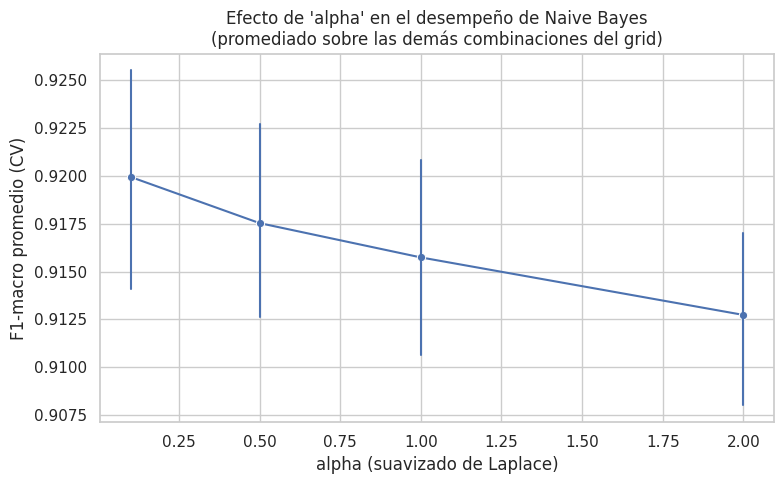

In [90]:
cv_results_nb = pd.DataFrame(busqueda_nb.cv_results_)

plt.figure()
sns.lineplot(
    data=cv_results_nb, x="param_clf__alpha", y="mean_test_score",
    marker="o", err_style="bars"
)
plt.title("Efecto de 'alpha' en el desempeño de Naive Bayes\n(promediado sobre las demás combinaciones del grid)")
plt.xlabel("alpha (suavizado de Laplace)")
plt.ylabel("F1-macro promedio (CV)")
plt.tight_layout()
plt.show()


In [ ]:
cv_results_lr = pd.DataFrame(busqueda_lr.cv_results_)
cv_results_lr["param_clf__C"] = cv_results_lr["param_clf__C"].astype(float)

plt.figure()
sns.lineplot(
    data=cv_results_lr, x="param_clf__C", y="mean_test_score",
    marker="o", err_style="bars"
)
plt.xscale("log")
plt.title("Efecto de 'C' en el desempeño de Regresión Logística\n(promediado sobre las demás combinaciones del grid)")
plt.xlabel("C (escala logarítmica)")
plt.ylabel("F1-macro promedio (CV)")
plt.tight_layout()
plt.show()


**Para discutir:** ¿Se nota alguna forma de "U invertida" en los gráficos? Eso sería evidencia de **overfitting** en un extremo (modelo demasiado flexible, `C` muy alto o `alpha` muy bajo) y **underfitting** en el otro (modelo demasiado rígido).

### 🔧 EJERCICIO
Elegí uno de los dos grids (`grid_nb` o `grid_lr`) y agregale un valor extra a alguno de los hiperparámetros (por ejemplo, `"clf__alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]`). Volvé a correr la búsqueda y fijate si cambia el mejor resultado.


---
# Bloque 7 · Evaluación final, interpretación y análisis de errores

Elegimos el mejor modelo encontrado (entre la búsqueda de Naive Bayes y la de Regresión Logística) y lo analizamos en profundidad sobre el conjunto de test, que **todavía no usamos para tomar ninguna decisión** (ni de preprocesamiento, ni de hiperparámetros) — así garantizamos una evaluación honesta.


In [106]:

mejor_busqueda = busqueda_nb
nombre_mejor_modelo = "Naive Bayes"
print(f"Mejor modelo global: {nombre_mejor_modelo}")
print("Mejores hiperparámetros:", mejor_busqueda.best_params_)

mejor_modelo_final = mejor_busqueda.best_estimator_
y_pred_final = mejor_modelo_final.predict(texto_test_final)

print("\n=== Reporte de clasificación en TEST ===")
print(classification_report(y_test, y_pred_final))


Mejor modelo global: Naive Bayes
Mejores hiperparámetros: {'clf__alpha': 0.1, 'tfidf__max_features': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}

=== Reporte de clasificación en TEST ===
                    precision    recall  f1-score   support

     comp.graphics       0.92      0.95      0.93       237
  rec.sport.hockey       0.98      0.98      0.98       243
         sci.space       0.93      0.90      0.91       238
talk.politics.guns       0.95      0.96      0.95       220

          accuracy                           0.95       938
         macro avg       0.95      0.95      0.95       938
      weighted avg       0.95      0.95      0.95       938



### 7.1 Matriz de confusión

La matriz de confusión muestra, para cada clase real (filas), qué clase predijo el modelo (columnas). La diagonal son los aciertos; todo lo que está fuera de la diagonal son errores, y nos dice **con qué otra clase se confunde** cada categoría.


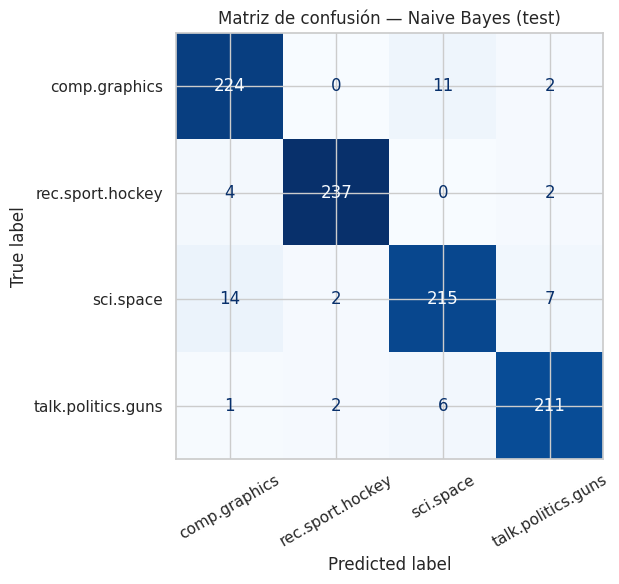

In [107]:
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_pred_final, labels=mejor_modelo_final.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=mejor_modelo_final.classes_)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=30, colorbar=False)
plt.title(f"Matriz de confusión — {nombre_mejor_modelo} (test)")
plt.tight_layout()
plt.show()


### 7.2 ¿Qué palabras usa el modelo para decidir?

Una de las grandes ventajas de estos modelos (frente a modelos "caja negra") es que podemos mirar **qué palabras pesan más para cada clase**.

- En **Regresión Logística**, cada palabra tiene un coeficiente (`coef_`) por clase: cuanto más alto (positivo), más "empuja" hacia esa clase.
- En **Naive Bayes**, `feature_log_prob_` nos da el logaritmo de la probabilidad de cada palabra dado cada clase; las palabras con mayor probabilidad relativa son las más características de esa clase.


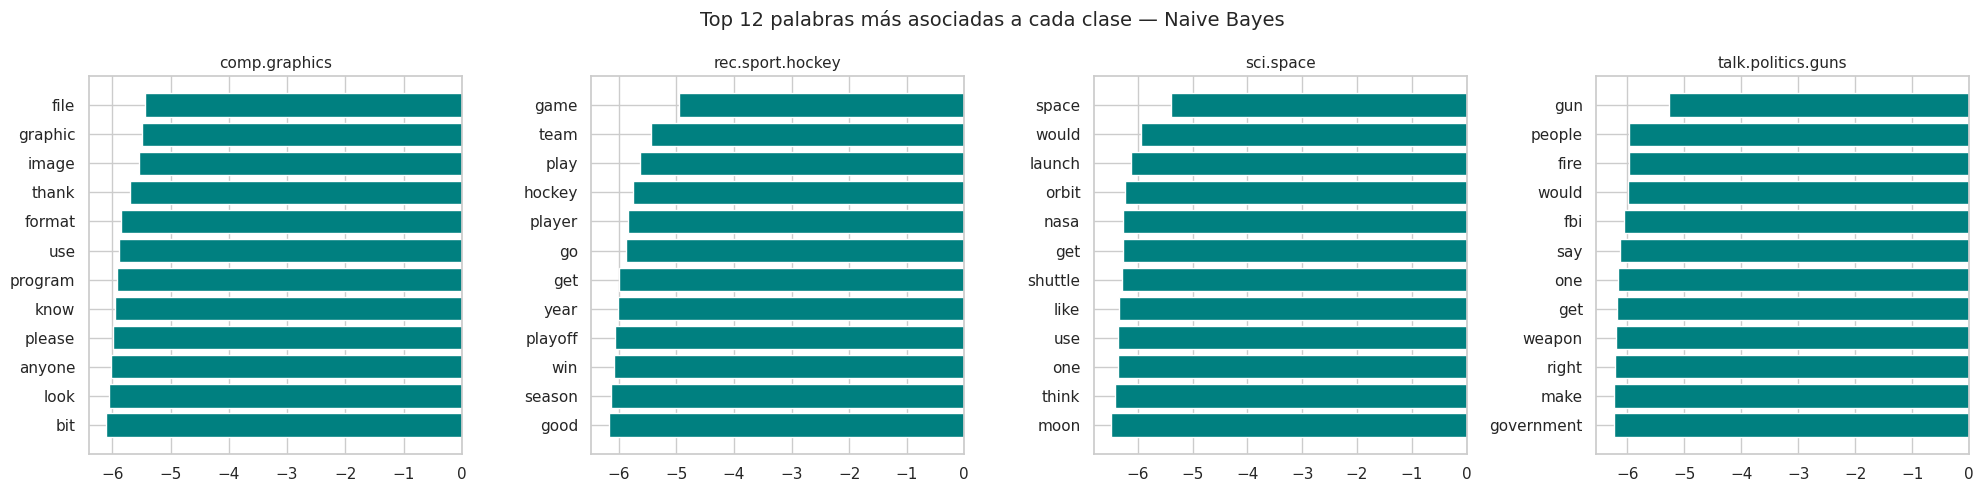

In [108]:
clf_final = mejor_modelo_final.named_steps["clf"]
vectorizador_final = mejor_modelo_final.named_steps["tfidf"]
vocabulario = np.array(vectorizador_final.get_feature_names_out())

def top_palabras_por_clase(n=12):
    fig, axes = plt.subplots(1, len(clf_final.classes_), figsize=(5 * len(clf_final.classes_), 5), sharex=False)

    for i, clase in enumerate(clf_final.classes_):
        if nombre_mejor_modelo == "Regresión Logística":
            pesos = clf_final.coef_[i]
        else:  # Naive Bayes
            pesos = clf_final.feature_log_prob_[i]

        top_idx = np.argsort(pesos)[-n:]
        ax = axes[i] if len(clf_final.classes_) > 1 else axes
        ax.barh(vocabulario[top_idx], pesos[top_idx], color="teal")
        ax.set_title(clase, fontsize=11)

    plt.suptitle(f"Top {n} palabras más asociadas a cada clase — {nombre_mejor_modelo}", fontsize=14)
    plt.tight_layout()
    plt.show()

top_palabras_por_clase()


**Para discutir:** ¿tienen sentido esas palabras para cada categoría? Este tipo de chequeo (`"sanity check"`) es muy útil para detectar si el modelo está aprendiendo señales reales o "atajos" espurios del dataset (por ejemplo, si todos los documentos de una clase tuvieran una firma o encabezado particular que se coló en el texto).

### 7.3 Visualizando los documentos en 2D

Para tener una intuición visual de qué tan "separables" son las clases en el espacio de features, podemos reducir la matriz TF-IDF (que tiene miles de dimensiones) a solo 2 dimensiones usando **`TruncatedSVD`** (una técnica de reducción de dimensionalidad que funciona bien con matrices dispersas como las de texto, a diferencia de PCA clásico).


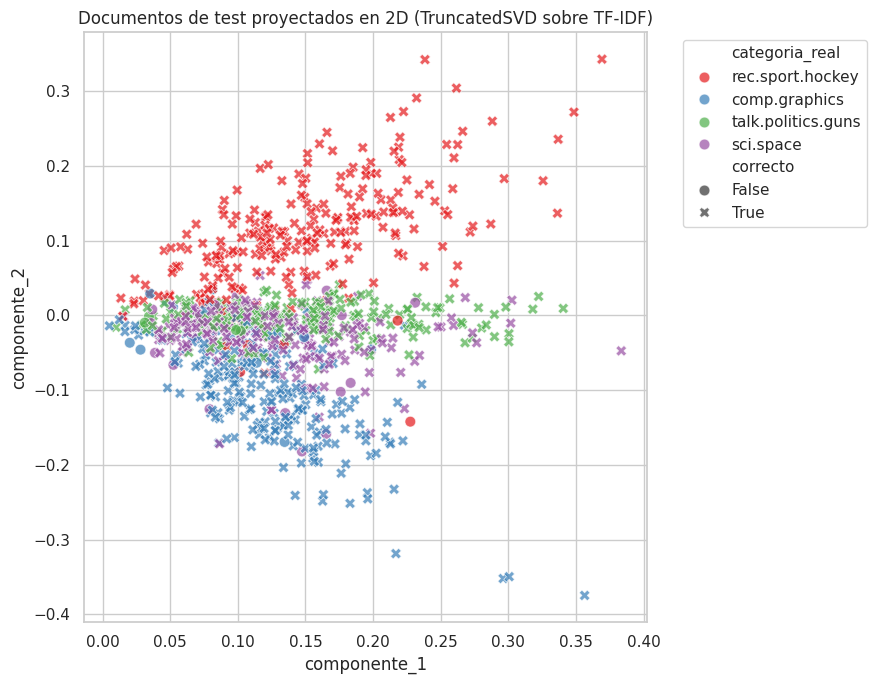

In [109]:
X_test_vec_final = vectorizador_final.transform(texto_test_final)

svd = TruncatedSVD(n_components=2, random_state=42)
X_test_2d = svd.fit_transform(X_test_vec_final)

df_2d = pd.DataFrame(X_test_2d, columns=["componente_1", "componente_2"])
df_2d["categoria_real"] = y_test.values
df_2d["prediccion"] = y_pred_final
df_2d["correcto"] = df_2d["categoria_real"] == df_2d["prediccion"]

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df_2d, x="componente_1", y="componente_2",
    hue="categoria_real", style="correcto", palette="Set1", alpha=0.7, s=60
)
plt.title("Documentos de test proyectados en 2D (TruncatedSVD sobre TF-IDF)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


Los puntos marcados con un símbolo distinto (`correcto = False`) son los que el modelo clasificó mal. Si están mezclados en la frontera entre dos nubes de puntos de colores distintos, tiene sentido: son los casos "más difíciles" de separar, incluso para nosotros mirando el gráfico.

### 7.4 Análisis de errores concretos

Miremos texto real de documentos que el modelo clasificó mal. Este paso — leer los errores a mano — es una de las prácticas más subestimadas (¡y más útiles!) en proyectos reales de NLP.


In [112]:
df_test_final = pd.DataFrame({
    "texto": df_muestra.loc[X_test.index, "texto"].values,
    "categoria_real": y_test.values,
    "prediccion": y_pred_final,
})

errores = df_test_final[df_test_final["categoria_real"] != df_test_final["prediccion"]]
print(f"Cantidad de errores en test: {len(errores)} de {len(df_test_final)} ({len(errores)/len(df_test_final):.1%})")

for _, fila in errores.sample(min(5, len(errores)), random_state=1).iterrows():
    print("-" * 80)
    print(f"REAL: {fila['categoria_real']}   |   PREDICHO: {fila['prediccion']}")
    print(fila["texto"][:2000], "...")


Cantidad de errores en test: 51 de 938 (5.4%)
--------------------------------------------------------------------------------
REAL: comp.graphics   |   PREDICHO: sci.space
Look in the /pub/SPACE directory on ames.arc.nasa.gov - there are a number
of earth images there. You may have to hunt around the subdirectories as
things tend to be filed under the mission (ie, "APOLLO") rather than under	
the image subject.	 ...
--------------------------------------------------------------------------------
REAL: comp.graphics   |   PREDICHO: sci.space


Which distance? The distance between one point (t = ti) on the first curve
and a point on the other curve with same parameter (u = ti)? ...
--------------------------------------------------------------------------------
REAL: sci.space   |   PREDICHO: rec.sport.hockey

...

How can you tell they're identical?

You got one of them "Star Drek: The Next Syndication" neutrino
scanners? ...
------------------------------------------------------------

**Para discutir en clase:** ¿los errores parecen "razonables" (documentos ambiguos, que mezclan temas) o parecen errores "tontos" del modelo? ¿Qué harías distinto si este fuera un proyecto real y tuvieras que mejorar estos resultados?

### 7.5 Probando el modelo con texto nuevo

Por último, armemos una función simple para clasificar una oración cualquiera, como si fuéramos un usuario final del sistema.


In [113]:
# Usamos la MISMA función de preprocesamiento con la que se entrenó el mejor modelo
funciones_preprocesamiento = {
    "Básico": preprocesar_basico,
    "Sin stopwords": preprocesar_stopwords,
    "Stemming": preprocesar_stemming,
    "Lematización": preprocesar_lematizacion,
}
preprocesamiento_final = funciones_preprocesamiento[mejor_fila["preprocesamiento"]]
print(f"El mejor modelo se entrenó con el preprocesamiento: '{mejor_fila['preprocesamiento']}'")


El mejor modelo se entrenó con el preprocesamiento: 'Lematización'


In [114]:
def predecir_categoria(texto_nuevo, modelo=mejor_modelo_final, preprocesamiento=preprocesamiento_final):
    texto_procesado = preprocesamiento(texto_nuevo)
    prediccion = modelo.predict([texto_procesado])[0]
    probabilidades = modelo.predict_proba([texto_procesado])[0]

    print(f"Texto: {texto_nuevo}")
    print(f"Predicción: {prediccion}\n")
    for clase, prob in sorted(zip(modelo.classes_, probabilidades), key=lambda x: -x[1]):
        print(f"  {clase:25s} {prob:.2%}")

predecir_categoria("The goalie made an incredible save in the third period.")


Texto: The goalie made an incredible save in the third period.
Predicción: rec.sport.hockey

  rec.sport.hockey          91.43%
  talk.politics.guns        4.22%
  sci.space                 2.97%
  comp.graphics             1.38%


In [ ]:
# 🔧 EJERCICIO: probá con tus propias frases (en inglés, ya que el dataset está en ese idioma)
predecir_categoria("NASA is planning a new mission to explore the surface of Mars.")


---
# Bloque 8 · Guardado del modelo, conclusiones y ejercicios

## 8.1 Guardando el modelo entrenado

En un proyecto real, no queremos re-entrenar el modelo cada vez: lo entrenamos una vez y lo guardamos en disco con `joblib`, para poder cargarlo después en otra notebook, un script o una API.


In [ ]:
import joblib

joblib.dump(mejor_modelo_final, "modelo_clasificador_texto.joblib")
print("Modelo guardado como 'modelo_clasificador_texto.joblib'")

# Para cargarlo en otro momento:
# modelo_cargado = joblib.load("modelo_clasificador_texto.joblib")


## 8.2 Resumen de lo que vimos

1. **EDA de texto**: balance de clases, longitud de documentos, nubes de palabras.
2. **Preprocesamiento**: limpieza, tokenización, stopwords, stemming vs. lematización — y comprobamos empíricamente su impacto real en el modelo (¡no siempre "más preprocesamiento" es mejor!).
3. **Vectorización**: CountVectorizer (conteos simples) vs. TF-IDF (pondera por qué tan distintiva es cada palabra).
4. **Modelos**: Naive Bayes (probabilístico, rápido, supuesto de independencia) vs. Regresión Logística (discriminativo, pesos interpretables).
5. **Metodología rigurosa**: barrido sistemático de combinaciones, `Pipeline` + `GridSearchCV` con validación cruzada para buscar hiperparámetros sin hacer *data leakage*.
6. **Interpretación y error analysis**: mirar qué palabras pesan más por clase, visualizar los documentos en 2D, y leer a mano los errores del modelo.

## 8.3 Ejercicios para seguir practicando (fuera de la clase)

1. **Cambiá de dataset**: probá con `fetch_20newsgroups` pero eligiendo 2 categorías muy parecidas entre sí (por ejemplo `"comp.sys.ibm.pc.hardware"` y `"comp.sys.mac.hardware"`). ¿El accuracy baja? ¿Por qué tendría sentido que baje?
2. **Agregá un tercer modelo**: probá `SGDClassifier` o `SVC` (Support Vector Machine) de `sklearn` y sumalo a la comparación del Bloque 5.
3. **Bigrams y trigrams**: ampliá el `ngram_range` a `(1, 3)` en el mejor pipeline encontrado. ¿Mejora o empeora? ¿Qué pasa con el tiempo de entrenamiento?
4. **Curva de aprendizaje**: entrenando con 10%, 25%, 50%, 75% y 100% del set de entrenamiento, graficá cómo cambia el F1 en test. ¿El modelo se beneficiaría de tener más datos?
5. **Adaptalo a español**: conseguí un dataset de noticias o reseñas en español (por ejemplo, de Kaggle) y adaptá las funciones de preprocesamiento (`stopwords.words("spanish")`, `SnowballStemmer("spanish")`, modelo `es_core_news_sm` de spaCy).

## 8.4 Recursos para seguir aprendiendo

- Documentación de `scikit-learn` sobre texto: https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
- Documentación de `nltk`: https://www.nltk.org/
- Documentación de `spaCy`: https://spacy.io/usage/linguistic-features#lemmatization
- Libro gratuito *"Speech and Language Processing"* (Jurafsky & Martin) — el capítulo de clasificación de texto y Naive Bayes es una referencia clásica: https://web.stanford.edu/~jurafsky/slp3/
